# Rate und Metriken: welche Metrik folgt der Rate?

Frage: Welche label-freie Metrik hängt am engsten mit der Rate zusammen, wenn das Ziel nur ist,
**Posterior Collapse zu verhindern**? Downstream-AUC wird hier bewusst **nicht** verwendet.

Daten: TCGA-Sweep `new_results_2026-09-29/biology_breakpoints_2026_09_29` (240 Läufe:
d ∈ {2, 4, 6, 8, 12, 16}, Seeds 13/17/23/31, je 10 β-Werte, festes β, keine Annealing-Läufe).
Rate = `posterior_conditional_kl_total_mean`, mittlere Gesamt-KL in Nats pro Patient (Test).

Drei Kennzahlen pro Metrik:
- **Pearson gegen log₁₀ Rate**, gepoolt über alle Läufe. Log, weil die Rate über fünf Größenordnungen läuft.
- **Spearman gegen die Rate**, gepoolt über alle Läufe. Unabhängig von der Transformation.
- **Distanzkorrelation (dCor) gegen log₁₀ Rate**, gepoolt und je Trajektorie (Median). dCor (Székely et al. 2007)
  ist genau dann 0, wenn Metrik und Rate unabhängig sind, und erfasst auch nichtmonotone Zusammenhänge
  (z. B. Cohesiveness, die beim Collapse wieder steigt). Sie hat kein Vorzeichen und liegt in [0, 1].
  Anders als Spearman hängt sie von der Skala ab, deshalb log₁₀ Rate wie bei Pearson.
  **Kleine Stichproben:** Die gewöhnliche dCor ist positiv verzerrt; bei n = 10 unabhängigen Werten liegt sie
  im Median schon bei ≈ 0,49 (95 %-Quantil ≈ 0,70). Je Trajektorie wird deshalb die **bias-korrigierte dCor²**
  (U-Statistik, `dcor.u_distance_correlation_sqr`, Erwartungswert 0 bei Unabhängigkeit, kann negativ werden)
  verwendet. Gepoolt (n = 240) ist die Verzerrung klein (Unabhängigkeit: Median ≈ 0,11) und die gewöhnliche dCor bleibt.
- **Spearman je Trajektorie**: Spearman über β innerhalb jeder (d, Seed)-Kombination, davon Median und
  Anteil der Trajektorien mit |ρ| ≥ 0,9. Das ist die relevante Größe für einen Annealer, der **innerhalb eines
  Laufs** β verändert. Die gepoolten Werte sind durch d verzerrt: Die Rate skaliert mit d, die meisten Metriken nicht.

Ausgeschlossen: Downstream-Werte, AUTOENCODIX-Losses, die Rate selbst, Konfigurationsspalten.
`graph_delta_*` ist exakt `graph_latent_*` minus einer Input-Konstante; solche Duplikate werden markiert.
Rekonstruktion ist enthalten, aber keine unabhängige Größe: Sie ist die andere Hälfte des Loss.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
import dcor
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "beta_vae_experiments":
    PROJECT_ROOT = PROJECT_ROOT.parent
SWEEP = PROJECT_ROOT / "beta_vae_experiments/new_results_2026-09-29/biology_breakpoints_2026_09_29/experiment_metrics.csv"
OUTPUT_ROOT = PROJECT_ROOT / "beta_vae_experiments/outputs/rate_metric_correlation"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True})

RATE = "posterior_conditional_kl_total_mean"
runs = pd.read_csv(SWEEP)
runs = runs[runs.status.eq("ok")].copy()
runs["log_rate"] = np.log10(runs[RATE])
assert np.isfinite(runs.log_rate).all() and len(runs) == 240
print(len(runs), "Läufe;", runs.groupby(["latent_dim", "seed"]).ngroups, "Trajektorien")
print("Rate von", runs[RATE].min().round(3), "bis", runs[RATE].max().round(0), "Nats")

240 Läufe; 24 Trajektorien
Rate von 0.0 bis 10180.0 Nats


## 1. Metrikfamilien und Ausschlüsse

In [2]:
EXCLUDE = ("downstream", "autoencodix", "learning_rate", RATE, "log_rate", "seed", "latent_dim", "beta",
           "epoch", "runtime", "time")
FAMILIES = {"recon": "Rekonstruktion", "geometry": "Geometrie (ZADU u. a.)", "graph": "Graph (kNN)",
            "topology": "Topologie (PH)", "posterior": "Posterior / Collapse", "dimensionality": "Dimensionalität"}

def family(metric):
    return FAMILIES.get(metric.split("_")[0], "andere")

candidates = [c for c in runs.select_dtypes("number").columns if not any(e in c for e in EXCLUDE)]
rows = []
for metric in candidates:
    values = runs[metric]
    valid = values.notna() & np.isfinite(values)
    if valid.sum() < 150 or values[valid].nunique() < 10:
        continue  # zu wenige gültige oder praktisch konstante Werte
    subset = runs[valid]
    trajectories = [spearmanr(group[metric], group[RATE]).statistic
                    for _, group in subset.groupby(["latent_dim", "seed"]) if group[metric].nunique() > 2]
    trajectories = np.asarray(trajectories, dtype=float)
    dcor_traj = [dcor.u_distance_correlation_sqr(group[metric].to_numpy(float), group.log_rate.to_numpy(float))
                 for _, group in subset.groupby(["latent_dim", "seed"]) if group[metric].nunique() > 2]
    rows.append(dict(
        metric=metric, family=family(metric), n=int(valid.sum()),
        pearson_log_rate=pearsonr(subset[metric], subset.log_rate).statistic,
        spearman_pooled=spearmanr(subset[metric], subset[RATE]).statistic,
        dcor_pooled=dcor.distance_correlation(subset[metric].to_numpy(float), subset.log_rate.to_numpy(float)),
        dcor2_traj_median=np.nanmedian(dcor_traj),
        spearman_traj_median=np.nanmedian(trajectories),
        spearman_traj_q25=np.nanquantile(trajectories, .25),
        spearman_traj_q75=np.nanquantile(trajectories, .75),
        traj_abs_ge_0p9=np.nanmean(np.abs(trajectories) >= .9),
        n_traj=int(np.isfinite(trajectories).sum()),
    ))
table = pd.DataFrame(rows)

# Exakte Duplikate (z. B. graph_delta_* = graph_latent_* − Konstante) markieren, nicht stillschweigend löschen.
table["duplicate_of"] = None
kept = []
for index, metric in table.metric.items():
    for other in kept:
        both = runs[[metric, other]].dropna()
        if len(both) == table.loc[index, "n"] and abs(np.corrcoef(both[metric], both[other])[0, 1]) > 1 - 1e-9:
            table.loc[index, "duplicate_of"] = other
            break
    else:
        kept.append(metric)
table["abs_traj"] = table.spearman_traj_median.abs()
table = table.sort_values("abs_traj", ascending=False).reset_index(drop=True)
table.to_csv(OUTPUT_ROOT / "rate_metric_correlation.csv", index=False)
print(len(table), "Metriken,", table.duplicate_of.notna().sum(), "davon exakte Duplikate")
display(table.family.value_counts().to_frame("Anzahl"))

/home/nickok/Projects/MasterThesis/vae-beta-control/.venv/lib/python3.11/site-packages/dcor/_dcor_internals.py:191: RuntimeWarning: divide by zero encountered in scalar divide
  first_term /= (n_samples - 3)
/home/nickok/Projects/MasterThesis/vae-beta-control/.venv/lib/python3.11/site-packages/dcor/_dcor_internals.py:192: RuntimeWarning: divide by zero encountered in scalar divide
  second_term /= (n_samples - 2) * (n_samples - 3)
/home/nickok/Projects/MasterThesis/vae-beta-control/.venv/lib/python3.11/site-packages/dcor/_dcor_internals.py:193: RuntimeWarning: divide by zero encountered in scalar divide
  third_term /= (n_samples - 1) * (n_samples - 2) * (n_samples - 3)
/home/nickok/Projects/MasterThesis/vae-beta-control/.venv/lib/python3.11/site-packages/dcor/_dcor_internals.py:199: RuntimeWarning: invalid value encountered in scalar subtract
  return first_term - 2 * second_term + third_term


115 Metriken, 38 davon exakte Duplikate


,Anzahl
family,
Graph (kNN),72
Geometrie (ZADU u. a.),17
Rekonstruktion,10
Topologie (PH),8
Dimensionalität,5
Posterior / Collapse,3


## 2. Rangliste (ohne Duplikate)

Sortiert nach |Median-Spearman je Trajektorie|. Vorzeichen: positiv heißt, die Metrik steigt mit der Rate
(fällt also beim Collapse), negativ das Umgekehrte.

In [3]:
unique = table[table.duplicate_of.isna()]
columns = ["metric", "family", "n", "pearson_log_rate", "spearman_pooled", "dcor_pooled", "dcor2_traj_median", "spearman_traj_median",
           "spearman_traj_q25", "spearman_traj_q75", "traj_abs_ge_0p9"]
display(unique[columns].head(30).round(3))

,metric,family,n,pearson_log_rate,spearman_pooled,dcor_pooled,dcor2_traj_median,spearman_traj_median,spearman_traj_q25,spearman_traj_q75,traj_abs_ge_0p9
0,recon_test_mse,Rekonstruktion,240,-0.913,-0.892,0.922,0.971,-0.997,-1.000,-0.964,0.958
1,recon_val_mse,Rekonstruktion,240,-0.911,-0.896,0.921,0.968,-0.997,-1.000,-0.982,0.917
2,dimensionality_z_mle,Dimensionalität,240,-0.270,-0.322,0.307,0.900,-0.994,-1.000,-0.973,0.833
3,recon_train_explained_variance_uniform_average,Rekonstruktion,240,0.912,0.895,0.922,0.969,0.992,0.973,1.000,0.917
4,recon_train_mse,Rekonstruktion,240,-0.920,-0.896,0.928,0.968,-0.992,-1.000,-0.973,0.917
5,recon_train_r2_uniform_average,Rekonstruktion,240,0.912,0.895,0.922,0.969,0.992,0.973,1.000,0.917
7,graph_delta_clustering_k20,Graph (kNN),240,-0.919,-0.862,0.923,0.941,-0.988,-1.000,-0.961,0.833
8,recon_test_explained_variance_uniform_average,Rekonstruktion,240,0.906,0.870,0.915,0.963,0.986,0.936,1.000,0.917
9,topology_h1_persistence_entropy_mu,Topologie (PH),202,0.758,0.779,0.768,0.901,0.976,0.923,0.983,0.833
10,geometry_mu_mrre_false_zadu_k20,Geometrie (ZADU u. a.),240,0.930,0.810,0.936,0.876,0.970,0.915,0.988,0.792


## 3. Beste Metrik je Familie

Für einen Collapse-Wächter interessiert vor allem, ob es außerhalb von Rekonstruktion und Posterior-Größen
(die direkt aus dem Loss stammen) Signale gibt, die der Rate ebenso eng folgen.

In [4]:
best = (unique.sort_values("abs_traj", ascending=False).groupby("family").head(3)
        .sort_values(["family", "abs_traj"], ascending=[True, False]))
display(best[columns].round(3))

,metric,family,n,pearson_log_rate,spearman_pooled,dcor_pooled,dcor2_traj_median,spearman_traj_median,spearman_traj_q25,spearman_traj_q75,traj_abs_ge_0p9
2,dimensionality_z_mle,Dimensionalität,240,-0.270,-0.322,0.307,0.900,-0.994,-1.000,-0.973,0.833
23,dimensionality_mu_twonn,Dimensionalität,162,0.401,0.488,0.457,0.801,0.857,0.821,0.945,0.375
39,dimensionality_z_twonn,Dimensionalität,240,-0.147,-0.166,0.182,0.535,-0.794,-0.939,-0.493,0.458
10,geometry_mu_mrre_false_zadu_k20,Geometrie (ZADU u. a.),240,0.930,0.810,0.936,0.876,0.970,0.915,0.988,0.792
11,geometry_mu_trustworthiness_zadu_k20,Geometrie (ZADU u. a.),240,0.930,0.803,0.936,0.861,0.957,0.906,0.988,0.750
12,geometry_mu_lcmc_zadu_k20,Geometrie (ZADU u. a.),240,0.871,0.811,0.881,0.953,0.951,0.924,0.988,0.792
7,graph_delta_clustering_k20,Graph (kNN),240,-0.919,-0.862,0.923,0.941,-0.988,-1.000,-0.961,0.833
13,graph_directed_edge_jaccard_lcmc_related_k20,Graph (kNN),240,0.850,0.810,0.863,0.957,0.951,0.924,0.988,0.792
21,graph_hub_identity_spearman_k20,Graph (kNN),240,0.771,0.732,0.793,0.873,0.873,0.791,0.918,0.375
42,posterior_active_units_count_eps_0p01,Posterior / Collapse,240,0.531,0.470,0.570,0.824,0.780,0.701,0.814,0.000


## 4. Übersicht: gepoolt gegen je Trajektorie

Jeder Punkt ist eine Metrik. Rechts oben: folgt der Rate innerhalb eines Laufs **und** über d hinweg.
Rechts unten: folgt der Rate innerhalb eines Laufs, ist aber über d hinweg verschoben (absolute Schwelle
überträgt sich dann nicht zwischen Latentdimensionen).

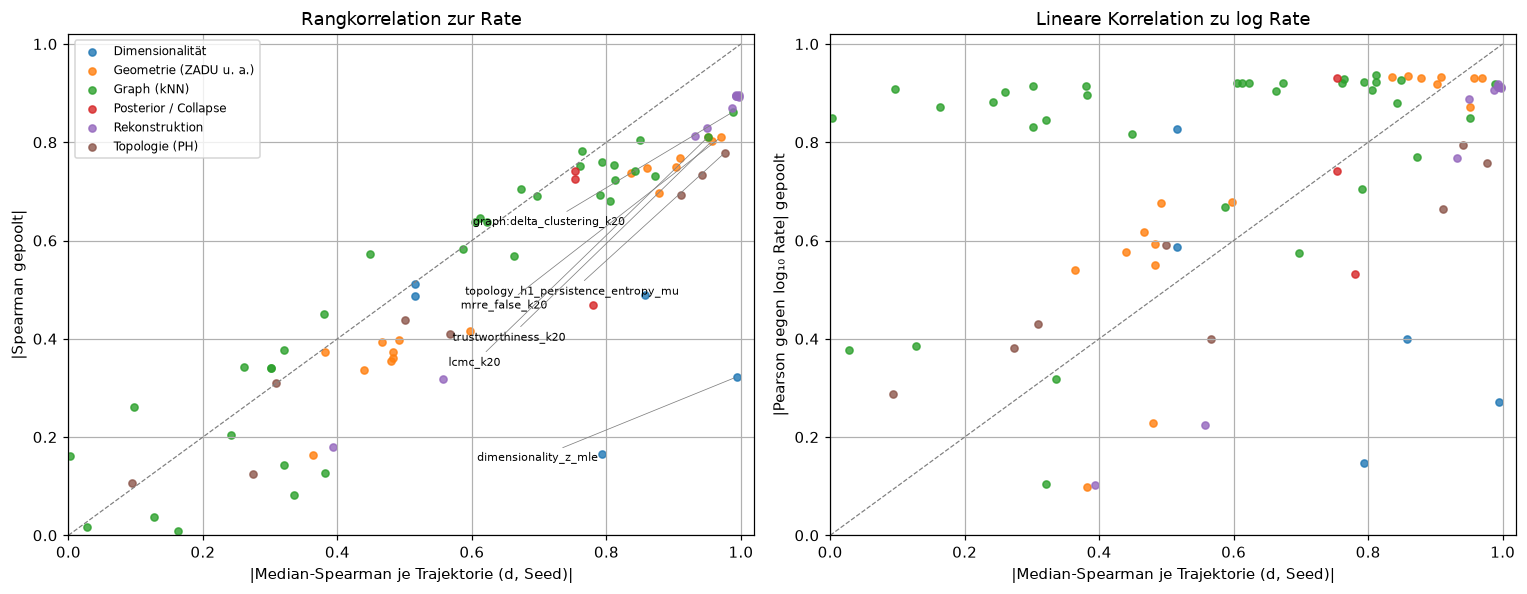

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, group in unique.groupby("family"):
    axes[0].scatter(group.spearman_traj_median.abs(), group.spearman_pooled.abs(), s=22, label=name, alpha=.8)
    axes[1].scatter(group.spearman_traj_median.abs(), group.pearson_log_rate.abs(), s=22, label=name, alpha=.8)
for ax, ylabel in zip(axes, ("|Spearman gepoolt|", "|Pearson gegen log₁₀ Rate| gepoolt")):
    ax.plot([0, 1], [0, 1], color="gray", lw=.8, ls="--")
    ax.set(xlabel="|Median-Spearman je Trajektorie (d, Seed)|", ylabel=ylabel, xlim=(0, 1.02), ylim=(0, 1.02))
labelled = unique[~unique.family.isin(["Rekonstruktion"])].head(6)
for offset, (_, row) in enumerate(labelled.iterrows()):
    short = row.metric.replace("geometry_mu_", "").replace("_zadu", "").replace("graph_", "graph:")
    axes[0].annotate(short, (abs(row.spearman_traj_median), abs(row.spearman_pooled)), fontsize=7,
                     xytext=(-170, -55 - 19 * offset), textcoords="offset points",
                     arrowprops=dict(arrowstyle="-", color="gray", lw=.5))
axes[0].legend(fontsize=8, loc="upper left")
axes[0].set_title("Rangkorrelation zur Rate")
axes[1].set_title("Lineare Korrelation zu log Rate")
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "overview_pooled_vs_trajectory.png", dpi=160)
plt.show()

## 4b. Distanzkorrelation zur Rate

Rangliste nach bias-korrigierter dCor² je Trajektorie (Median) und Vergleich mit ρ² (Spearman je Trajektorie,
quadriert, damit beide auf derselben Skala liegen). Liegt eine Metrik deutlich über der Diagonale, hängt sie stark,
aber **nicht monoton** von der Rate ab: Spearman unterschätzt sie dann (z. B. erst fallend, beim Collapse steigend).
Zur Einordnung des Nullniveaus wird dCor² für zufällig permutierte Rate-Werte mitberechnet.

Nullniveau dCor² je Trajektorie (permutierte Rate): Median -0.011, 95 %-Quantil 0.264


,metric,family,dcor_pooled,dcor2_traj_median,spearman_traj_median,pearson_log_rate
0,recon_test_mse,Rekonstruktion,0.922,0.971,-0.997,-0.913
5,recon_train_r2_uniform_average,Rekonstruktion,0.922,0.969,0.992,0.912
3,recon_train_explained_variance_uniform_average,Rekonstruktion,0.922,0.969,0.992,0.912
1,recon_val_mse,Rekonstruktion,0.921,0.968,-0.997,-0.911
4,recon_train_mse,Rekonstruktion,0.928,0.968,-0.992,-0.920
8,recon_test_explained_variance_uniform_average,Rekonstruktion,0.915,0.963,0.986,0.906
14,recon_test_r2_uniform_average,Rekonstruktion,0.895,0.957,0.950,0.887
13,graph_directed_edge_jaccard_lcmc_related_k20,Graph (kNN),0.863,0.957,0.951,0.850
12,geometry_mu_lcmc_zadu_k20,Geometrie (ZADU u. a.),0.881,0.953,0.951,0.871
7,graph_delta_clustering_k20,Graph (kNN),0.923,0.941,-0.988,-0.919


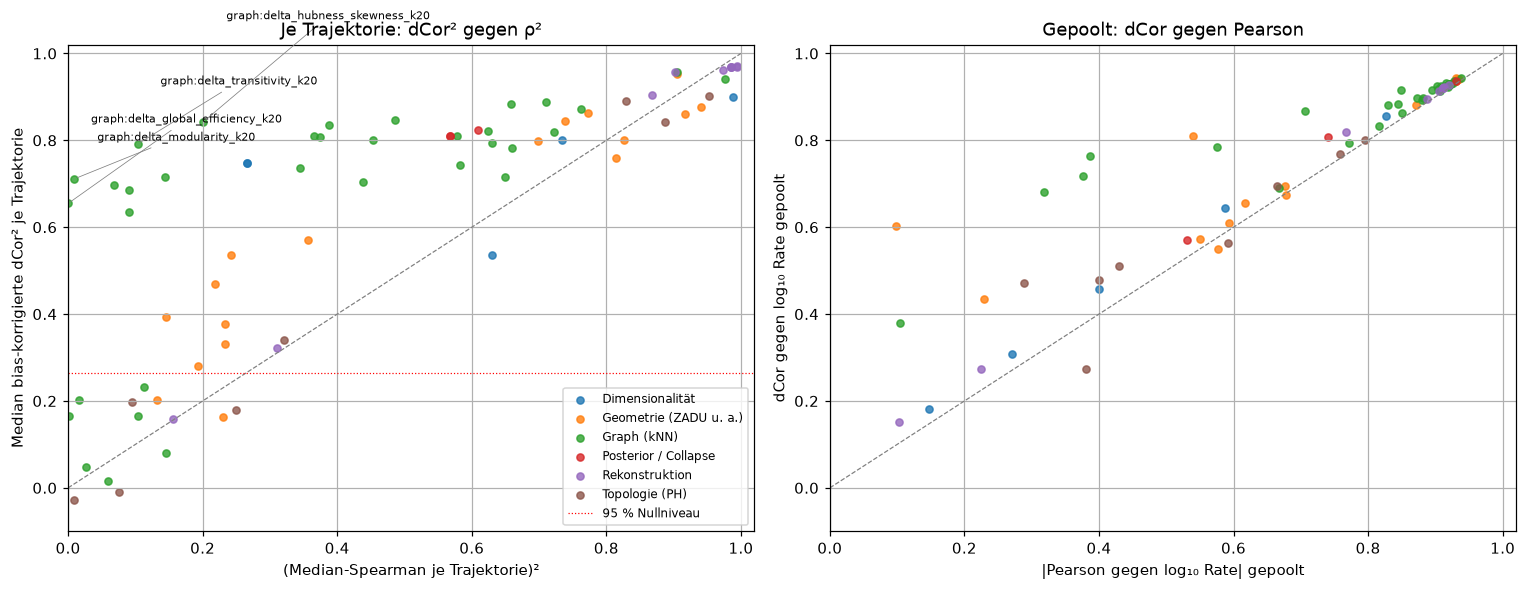

In [6]:
rng = np.random.default_rng(31)
null = [dcor.u_distance_correlation_sqr(group.geometry_mu_trustworthiness_zadu_k20.to_numpy(float),
                                        rng.permutation(group.log_rate.to_numpy(float)))
        for _ in range(50) for _, group in runs.groupby(["latent_dim", "seed"])]
print(f"Nullniveau dCor² je Trajektorie (permutierte Rate): Median {np.median(null):.3f}, 95 %-Quantil {np.quantile(null, .95):.3f}")
by_dcor = unique.sort_values("dcor2_traj_median", ascending=False)
display(by_dcor[["metric", "family", "dcor_pooled", "dcor2_traj_median", "spearman_traj_median", "pearson_log_rate"]]
        .head(25).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, group in unique.groupby("family"):
    axes[0].scatter(group.spearman_traj_median ** 2, group.dcor2_traj_median, s=22, alpha=.8, label=name)
    axes[1].scatter(group.pearson_log_rate.abs(), group.dcor_pooled, s=22, alpha=.8, label=name)
for ax, (xlabel, ylabel) in zip(axes, [("(Median-Spearman je Trajektorie)²", "Median bias-korrigierte dCor² je Trajektorie"),
                                        ("|Pearson gegen log₁₀ Rate| gepoolt", "dCor gegen log₁₀ Rate gepoolt")]):
    ax.plot([0, 1], [0, 1], color="gray", lw=.8, ls="--")
    ax.set(xlabel=xlabel, ylabel=ylabel, xlim=(0, 1.02), ylim=(min(-.1, unique.dcor2_traj_median.min() - .05), 1.02))
axes[0].axhline(np.quantile(null, .95), color="red", lw=.8, ls=":", label="95 % Nullniveau")
gap = unique.assign(gap=unique.dcor2_traj_median - unique.spearman_traj_median ** 2).nlargest(4, "gap")
for offset, (_, row) in enumerate(gap.iterrows()):
    short = row.metric.replace("geometry_mu_", "").replace("_zadu", "").replace("graph_", "graph:")
    axes[0].annotate(short, (row.spearman_traj_median ** 2, row.dcor2_traj_median), fontsize=7,
                     xytext=(15, 25 + 14 * offset), textcoords="offset points",
                     arrowprops=dict(arrowstyle="-", color="gray", lw=.5))
axes[0].set_title("Je Trajektorie: dCor² gegen ρ²")
axes[1].set_title("Gepoolt: dCor gegen Pearson")
axes[0].legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "dcor_vs_rank_correlation.png", dpi=160)
plt.show()

## 5. Ausgewählte Metriken gegen die Rate

Label-freie Kandidaten, die der Controller in `preservation_annealing.py` bereits messen kann
(Trustworthiness, MRRE false, LCMC, Cohesiveness), dazu die besten anderen Familien und zum Vergleich
die Rekonstruktion. Farbe = Latentdimension d, Linien verbinden die β-Werte einer Trajektorie in β-Reihenfolge.

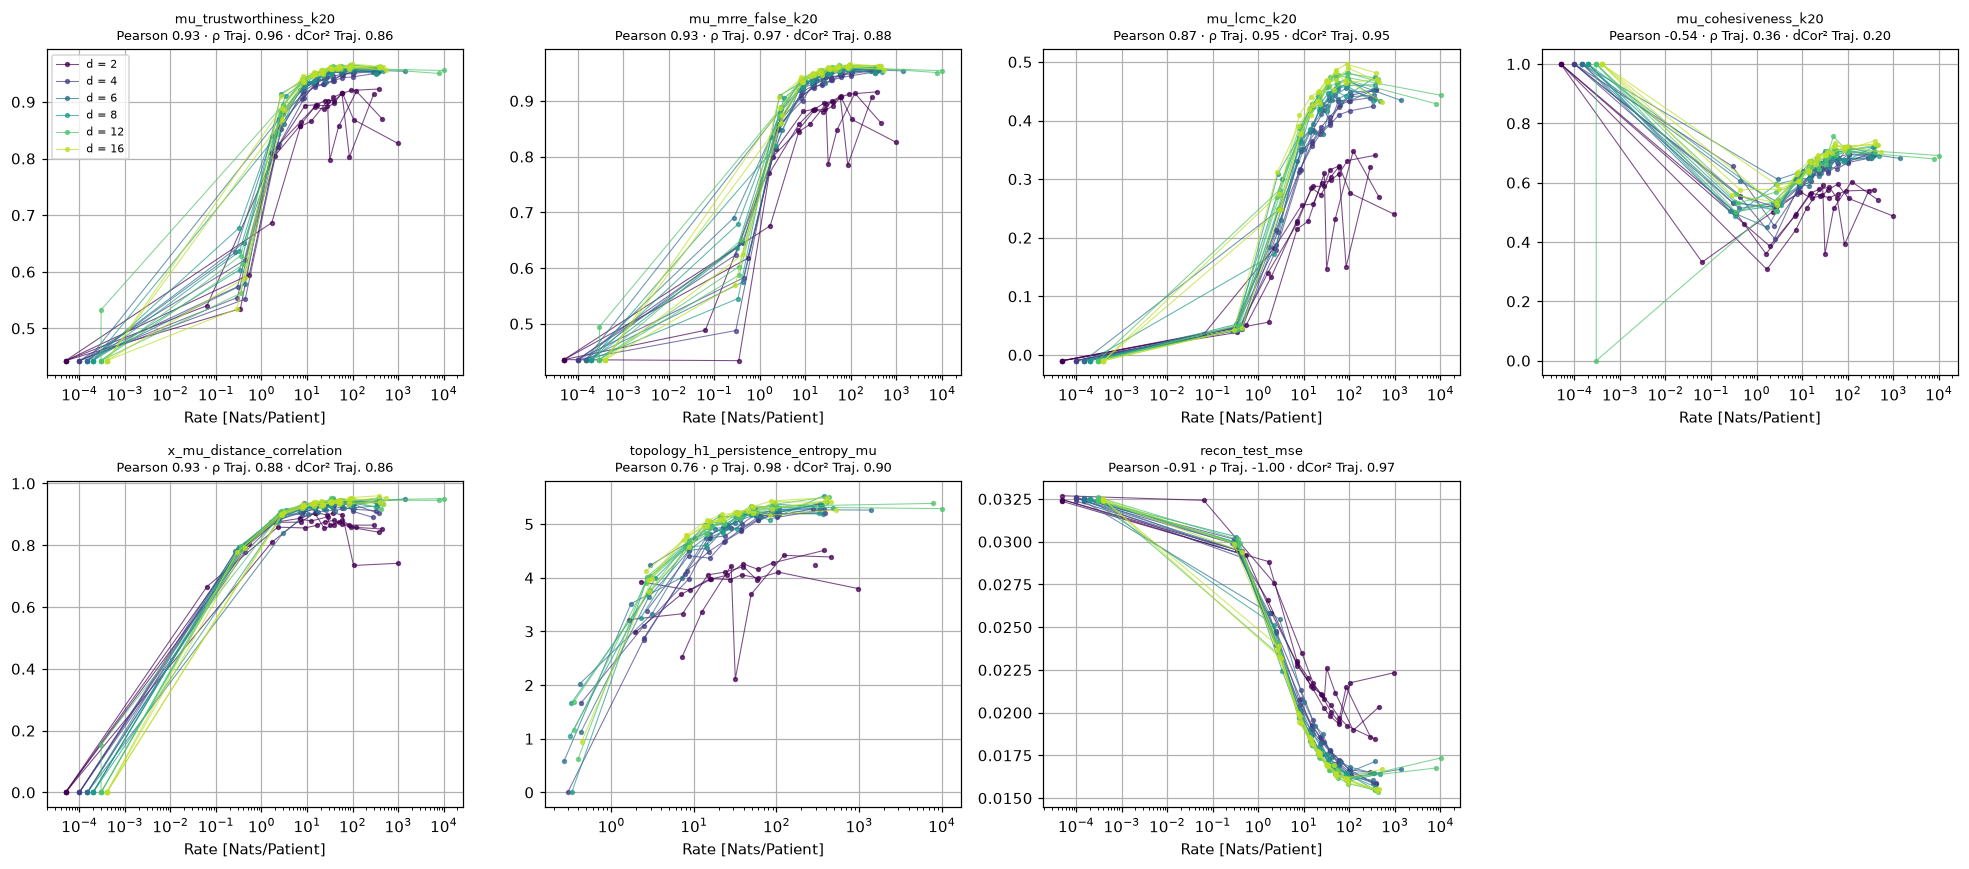

In [7]:
SHOWN = ["geometry_mu_trustworthiness_zadu_k20", "geometry_mu_mrre_false_zadu_k20", "geometry_mu_lcmc_zadu_k20",
         "geometry_mu_cohesiveness_zadu_k20", "geometry_x_mu_distance_correlation", "graph_latent_clustering_k20",
         "topology_h1_persistence_entropy_mu", "recon_test_mse"]
SHOWN = [m for m in SHOWN if m in set(unique.metric)]
dims = sorted(runs.latent_dim.unique())
colors = dict(zip(dims, plt.cm.viridis(np.linspace(0, .9, len(dims)))))
fig, axes = plt.subplots(2, 4, figsize=(18, 8), squeeze=False)
for ax, metric in zip(axes.flat, SHOWN):
    for (d, seed), group in runs.sort_values("beta").groupby(["latent_dim", "seed"]):
        ax.plot(group[RATE], group[metric], "-o", ms=2.5, lw=.7, color=colors[d], alpha=.7,
                label=f"d = {d}" if seed == runs.seed.min() else None)
    row = unique.set_index("metric").loc[metric]
    ax.set(xscale="log", xlabel="Rate [Nats/Patient]",
           title=f"{metric.replace('geometry_', '').replace('_zadu', '')}\n"
                 f"Pearson {row.pearson_log_rate:.2f} · ρ Traj. {row.spearman_traj_median:.2f} · dCor² Traj. {row.dcor2_traj_median:.2f}")
    ax.title.set_fontsize(8.5)
for ax in axes.flat[len(SHOWN):]:
    ax.axis("off")
axes.flat[0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "selected_metrics_vs_rate.png", dpi=160)
plt.show()

## 6. Direkte Collapse-Größen zum Vergleich

Wenn das Ziel nur Collapse-Vermeidung ist, kann man auch direkt messen: Anteil kollabierter Dimensionen
(ε-δ: ≥ 99 % der Patienten mit KL < 0,01 in der Dimension). Hier: Wie früh fängt eine Metrik an zu fallen,
bevor die erste Dimension kollabiert? Für jede Trajektorie wird der kleinste β gesucht, bei dem mindestens eine
Dimension kollabiert ist, und der Metrikwert beim β davor relativ zum Wert bei β = 0 berechnet.
Trajektorien, in denen schon der erste β > 0 kollabiert, fallen heraus (dort ist „davor“ β = 0 selbst).
„Bewegt“ heißt: Der Wert vor dem ersten Collapse weicht um mindestens 2 % vom Wert bei β = 0 ab, egal in welche Richtung.

In [8]:
COLLAPSE = "posterior_collapsed_dimensions_count_eps_0p01_delta_0p01"
early = []
for (d, seed), group in runs.sort_values("beta").groupby(["latent_dim", "seed"]):
    collapsed = group[group[COLLAPSE] > 0]
    if collapsed.empty or group.index.get_loc(collapsed.index[0]) < 2:
        continue  # kein Collapse im Raster, oder schon bei β = 0 bzw. beim ersten β > 0
    before = group.loc[:collapsed.index[0]].iloc[-2]
    reference = group.iloc[0]
    row = dict(latent_dim=d, seed=seed, beta_first_collapse=collapsed.iloc[0].beta,
               rate_before=before[RATE], rate_reference=reference[RATE])
    for metric in SHOWN:
        row[metric] = before[metric] / reference[metric] if reference[metric] else np.nan
    early.append(row)
early = pd.DataFrame(early)
early.to_csv(OUTPUT_ROOT / "metric_before_first_collapse.csv", index=False)
print(len(early), "Trajektorien mit beobachtetem Collapse-Beginn")
summary = early[SHOWN].median().to_frame("Median: Wert vor 1. Collapse / Wert bei β = 0")
summary["Anteil Trajektorien bewegt (≥ 2 %)"] = ((early[SHOWN] - 1).abs() >= .02).mean()
display(summary.round(3))
display(early[["latent_dim", "seed", "beta_first_collapse", "rate_before", "rate_reference"]].round(3))

22 Trajektorien mit beobachtetem Collapse-Beginn


,Median: Wert vor 1. Collapse / Wert bei β = 0,Anteil Trajektorien bewegt (≥ 2 %)
geometry_mu_trustworthiness_zadu_k20,0.973,0.591
geometry_mu_mrre_false_zadu_k20,0.970,0.682
geometry_mu_lcmc_zadu_k20,0.781,1.000
geometry_mu_cohesiveness_zadu_k20,0.863,1.000
geometry_x_mu_distance_correlation,0.988,0.409
topology_h1_persistence_entropy_mu,0.870,0.909
recon_test_mse,1.266,1.000


,latent_dim,seed,beta_first_collapse,rate_before,rate_reference
0,2,13,0.008,1.621,289.968
1,2,17,0.008,1.689,454.026
2,2,23,0.008,1.944,974.356
3,2,31,0.008,2.276,375.581
4,4,13,0.016,2.464,332.212
5,4,17,0.001,15.803,279.489
6,4,23,0.004,7.838,377.436
7,4,31,0.016,2.683,386.492
8,6,13,0.024,2.834,1385.675
9,6,17,0.000,31.671,370.347


## 7. Einordnung

**Wer folgt der Rate am engsten (je Trajektorie, Median-Spearman)?**
- Rekonstruktion (MSE −0,997, R² 0,99): fast deterministisch, aber keine unabhängige Größe, sondern die andere Hälfte des Loss.
- Intrinsische Dimension von z (MLE, −0,99): Wenn μ schrumpft, dominiert das isotrope Rauschen und die ID von z steigt auf d.
  Gepoolt nur −0,32, weil der Wert direkt von d abhängt; eine absolute Schwelle überträgt sich also nicht zwischen d.
- Graph-Clustering k = 20 (−0,99; gepoolt −0,86 / Pearson −0,92).
- **Label-freie Preservation-Maße:** H1-Persistenzentropie μ 0,98 (nur 202 Läufe gültig), **MRRE false 0,97**,
  **Trustworthiness 0,96**, LCMC 0,95. MRRE false und Trustworthiness haben auch gepoolt die höchsten Pearson-Werte
  (0,93) und übertragen sich am besten zwischen d. Distanzkorrelation 0,88, Steadiness 0,86.
- Cohesiveness folgt der Rate **nicht** monoton (0,36): Sie steigt beim vollständigen Collapse wieder auf 1.

**Distanzkorrelation (Abschnitt 4b).** Gepoolt liegen MRRE false, Trustworthiness, Steadiness, MRRE missing,
Distanzkorrelation X↔μ und Graph-NMI alle bei dCor ≈ 0,94 (Nullniveau ≈ 0,11) – dieselbe Spitzengruppe wie bei Pearson.
Je Trajektorie (bias-korrigierte dCor², Nullniveau 95 %-Quantil ≈ 0,26): Rekonstruktion 0,97, LCMC 0,95,
H1-Persistenzentropie 0,90, MRRE false 0,88, Trustworthiness 0,86. dCor bestätigt also die Spearman-Rangliste.
Neu sind nur einige Graph-Maße (Modularität, globale Effizienz, Transitivität), die stark, aber **nicht monoton**
mit der Rate zusammenhängen (dCor² 0,65–0,8 bei ρ ≈ 0): Sie fallen erst und springen beim Collapse zurück.
Für einen Schwellen-Wächter sind solche Signale ungeeignet, weil derselbe Wert vor und nach dem Collapse auftritt.
Cohesiveness ist auch nach dCor² je Trajektorie schwach (0,20).

**Form des Zusammenhangs (Abschnitt 5).** Alle Preservation-Maße sind über Rate ≈ 10–10⁴ Nats nahezu flach und
fallen steil zwischen etwa 5 und 0,3 Nats. Sie sind damit gute **Collapse-Detektoren**, aber blind dafür, ob die Rate
von 400 auf 20 Nats sinkt. d = 2 liegt durchgehend tiefer und streut stärker.

**Bewegen sie sich vor dem ersten kollabierten Dimension (Abschnitt 6, 22 Trajektorien)?** Median des Werts vor
dem ersten Collapse relativ zu β = 0: LCMC 0,78 (in 100 % der Trajektorien ≥ 2 % bewegt), H1-Entropie 0,87 (91 %),
Cohesiveness 0,86 (100 %), Trustworthiness 0,97 (59 %), MRRE false 0,97 (68 %), Distanzkorrelation 0,99 (41 %).
LCMC reagiert relativ am stärksten, weil es auf einer kleinen Skala (~0,45) liegt. Trustworthiness hat zwar die
engste Rangkorrelation, bewegt sich vor dem ersten Collapse aber oft um weniger als 2 % – das deckt sich mit dem
schmalen Fenster im Annealing-Lauf (Trust 0,96 → 0,94).

**Fazit für einen Collapse-Wächter.** Wer nur Collapse verhindern will, kann die Rate oder die kollabierten
Dimensionen direkt messen; das ist label-frei, billig und rauscht nicht. Unter den Ersatzgrößen sind MRRE false
und Trustworthiness die beste Kombination aus enger Rangkorrelation und Übertragbarkeit über d, LCMC das
empfindlichste Frühsignal. Grenzen: ein Datensatz (TCGA), 10 β-Stufen je Trajektorie, feste β-Läufe (kein Annealing),
Metriken auf μ des Test-Splits; der Zusammenhang ist Korrelation über β, kein Nachweis zeitlicher Frühwarnung.